In [ ]:
!pip install -q kagglehub
import kagglehub
import pandas as pd
import seaborn as sns
import numpy as np
import os
import matplotlib.pyplot as plt


path = kagglehub.dataset_download("debayank2024/house-price-prediction")
print("Path to dataset files:", path)


files = os.listdir(path)
print("Files in directory:", files)


csv_file = [f for f in files if f.endswith('.csv')][0]
full_csv_path = os.path.join(path, csv_file)

df = pd.read_csv(full_csv_path)


df.tail()

Using Colab cache for faster access to the 'house-price-prediction' dataset.
Path to dataset files: /kaggle/input/house-price-prediction
Files in directory: ['modified_data.csv']


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
4595,2014-07-09,308166.67,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,204.08
4596,2014-07-09,534333.33,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,365.98
4597,2014-07-09,416904.17,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,138.51
4598,2014-07-10,203400.00,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,97.32
4599,2014-07-10,220600.00,3.0,2.50,1490,8102,2.0,0,0,4,1490,0,1990,0,18717 SE 258th St,Covington,WA 98042,148.05


### Phase 1: Data Cleaning & Boundary Constraints
In this section, I inspect the raw structural features of the Washington State housing dataset.
To establish a stable baseline for standard residential properties, rows containing physical
or logging impossibilities—specifically properties listed with $0 valuation or 0 bathrooms—are
mathematically filtered out.

In [ ]:
df['bedrooms'].describe()

,bedrooms
count,4600.000000
mean,3.400870
std,0.908848
min,0.000000
25%,3.000000
50%,3.000000
75%,4.000000
max,9.000000


In [ ]:
df['bathrooms'].describe()

,bathrooms
count,4600.000000
mean,2.160815
std,0.783781
min,0.000000
25%,1.750000
50%,2.250000
75%,2.500000
max,8.000000


In [ ]:
df['price'].describe()

,price
count,4.600000e+03
mean,5.519630e+05
std,5.638347e+05
min,0.000000e+00
25%,3.228750e+05
50%,4.609435e+05
75%,6.549625e+05
max,2.659000e+07


In [ ]:
df = df.drop(df[df['bathrooms'] == 0].index)

In [ ]:
df = df.drop(df[df['price'] == 0].index)

In [ ]:
df[['price', 'bathrooms']].describe()

,price,bathrooms
count,4.549000e+03,4549.000000
mean,5.576257e+05,2.155968
std,5.638915e+05,0.775205
min,7.800000e+03,0.750000
25%,3.261000e+05,1.750000
50%,4.650000e+05,2.250000
75%,6.575000e+05,2.500000
max,2.659000e+07,8.000000


### Phase 2: Feature Engineering & Target Transformation
Real estate prices are heavily right-skewed, violating standard homoscedasticity assumptions
required for linear modeling.

To address this, I implemented a two-step optimization pipeline:
1. Applied the Interquartile Range (IQR) method dynamically to clip extreme luxury outliers.
2. Utilized a natural logarithmic transformation (`np.log1p`) on the target pricing column.

Additionally, I engineered a custom `house_age` factor using vectorized NumPy logic to resolve
an anomaly where unrenovated homes default to a year value of 0. Identifiers and pricing derivative
metrics are explicitly dropped to eliminate data leakage.


In [ ]:
Q1=3.261000e+05
Q3=6.575000e+05
IQR = Q3 - Q1
print(IQR)

331400.0


In [ ]:
lower_bound = Q1-(1.5*IQR)
df = df.drop(df[df['price'] < lower_bound].index)

In [ ]:
upper_bound = Q3+(1.5*IQR)
df = df.drop(df[df['price'] > upper_bound].index)

In [ ]:
df['log_price']= np.log1p(df['price'])

Text(0, 0.5, 'y')

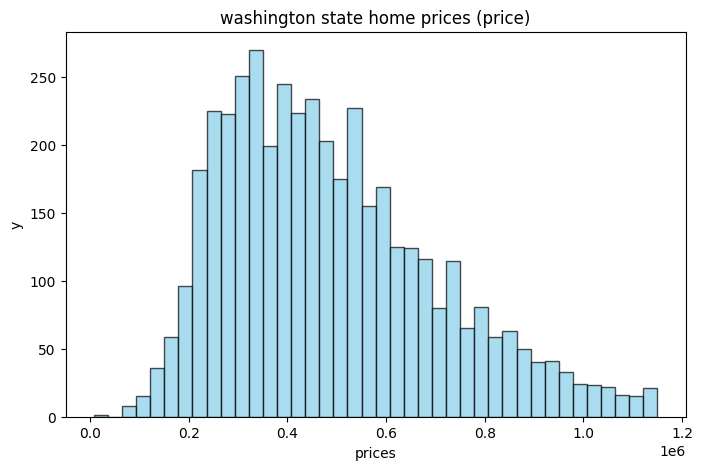

In [ ]:
data = df['price']
plt.figure(figsize=(8,5))
plt.hist(data, bins=40,color='skyblue',edgecolor='black',alpha=0.7)
plt.title("washington state home prices (price)")
plt.xlabel("prices")
plt.ylabel("y")

Text(0, 0.5, 'y')

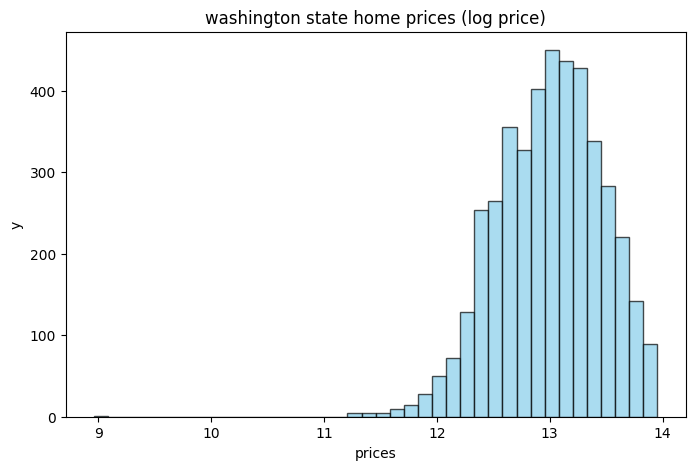

In [ ]:
data = df['log_price']
plt.figure(figsize=(8,5))
plt.hist(data, bins=40,color='skyblue',edgecolor='black',alpha=0.7)
plt.title("washington state home prices (log price)")
plt.xlabel("prices")
plt.ylabel("y")

In [ ]:
#Bounds calculated earlier in notebook
print(f"Lower Filter Bound: {lower_bound}")
print(f"Upper Filter Bound: {upper_bound}")

#The numeric skewness scores of Raw Price vs. Log Price
print(f"Raw Price Skew: {df['price'].skew():.2f}")
print(f"Log Price Skew: {df['log_price'].skew():.2f}")

Lower Filter Bound: -171000.0
Upper Filter Bound: 1154600.0
Raw Price Skew: 0.73
Log Price Skew: -0.42


In [ ]:
X = df.drop(axis=1, columns=['price', 'log_price', 'date', 'street', 'city', 'statezip', 'price_per_sqft'])
print(X.columns)

Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated'],
      dtype='object')


In [ ]:
X['effective_year']=np.where(X['yr_renovated'] > 0, X['yr_renovated'], X['yr_built'])

X['house_age'] = 2015-X['effective_year']

X=X.drop(axis = 1, columns=['yr_built', 'yr_renovated', 'effective_year'])

In [ ]:
print(X.columns)

Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'house_age'],
      dtype='object')


In [ ]:
X[['house_age']].describe()

,house_age
count,4310.000000
mean,29.843155
std,26.701160
min,1.000000
25%,10.000000
50%,21.000000
75%,41.000000
max,115.000000


### Phase 3: Machine Learning Predictive Pipeline
Using `scikit-learn`, the engineered feature matrix (X) and target vector (y) are partitioned
into an 80% training set and a 20% testing set to evaluate generalization on unseen home profiles.
A baseline `LinearRegression` model is initialized and fitted to the training subsets.

Post-prediction, raw log-scale estimates are inverted back to standard USD currencies using `np.expm1()`.


In [ ]:
from sklearn.model_selection import train_test_split
X = df['sqft_living']
y = df['log_price']
X = X.to_frame()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [ ]:
from sklearn.linear_model import LinearRegression
wash_home_prices_lin_reg_model = LinearRegression()

In [ ]:
wash_home_prices_lin_reg_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
print("--- ENVIRONMENT SHAPE DIAGNOSTIC ---")
print(f"Master df shape:   {df.shape}")
print(f"Feature X type:    {type(X)}")
print(f"Feature X shape:   {X.shape}")
print(f"Target y type:     {type(y)}")
print(f"Target y shape:    {y.shape}")

--- ENVIRONMENT SHAPE DIAGNOSTIC ---
Master df shape:   (4310, 19)
Feature X type:    <class 'pandas.core.frame.DataFrame'>
Feature X shape:   (4310, 1)
Target y type:     <class 'pandas.core.series.Series'>
Target y shape:    (4310,)


In [ ]:
y_prices_pred_log= wash_home_prices_lin_reg_model.predict(X_test)

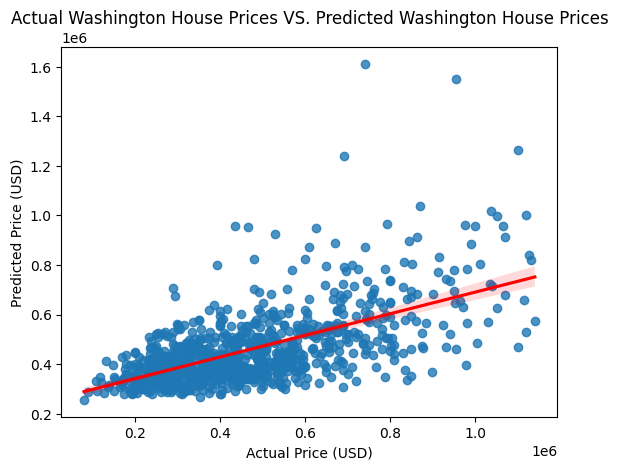

In [ ]:
y_prices_pred_usd = np.expm1(y_prices_pred_log)
y_prices_test_usd = np.expm1(y_test)

sns.regplot(x=y_prices_test_usd, y= y_prices_pred_usd, data=df, line_kws={'color': 'red'})
plt.title("Actual Washington House Prices VS. Predicted Washington House Prices")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.show()

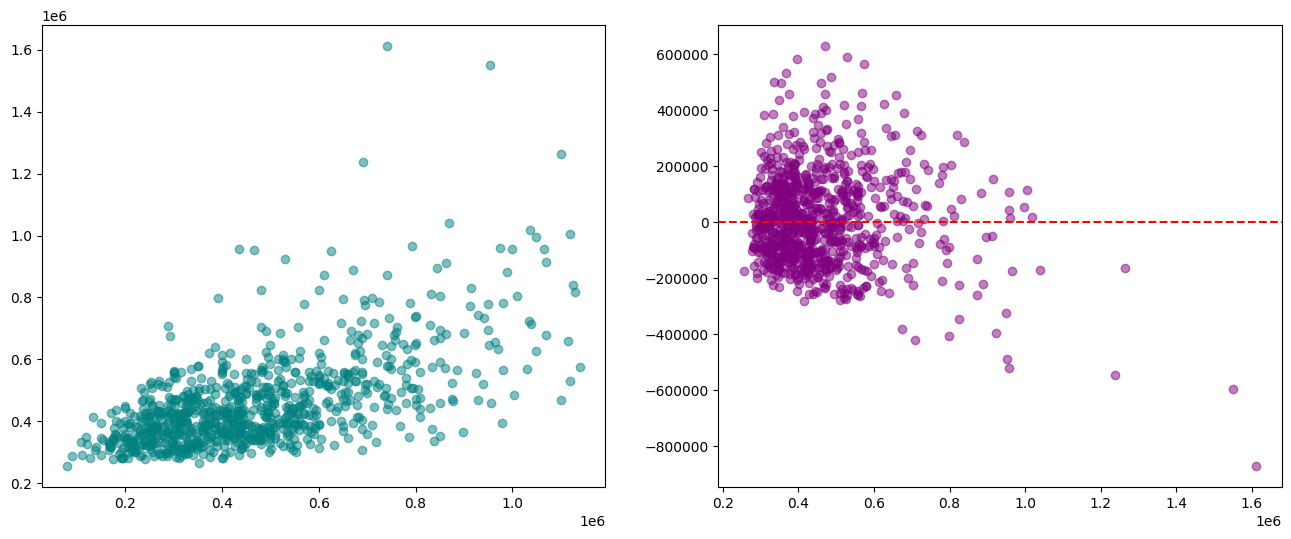

In [ ]:
actual= y_prices_test_usd
predicted = y_prices_pred_usd
residuals = actual-predicted

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


axes[0].scatter(x=actual, y=predicted, color='teal', alpha=0.5)

axes[1].scatter(x=predicted, y=residuals, color='purple', alpha=0.5)

axes[1].axhline(y=0, color='red', linestyle='--')



### Phase 4: Model Evaluation & Residual Diagnostics
To validate model performance, I calculated the Coefficient of Determination ($R^2$) and the
Root Mean Squared Error (RMSE).

A visual diagnostic check is executed via a residual plot. Symmetrical, random distribution of
prediction errors centered around the zero baseline confirms that the model satisfies necessary
linear assumptions and exhibits stable variance across all price tiers.


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
r2 =r2_score(y_test, y_prices_pred_log)
rmse = np.sqrt(mean_squared_error(y_prices_test_usd, y_prices_pred_usd))
print(f"R² Score: {r2:.4f}")
print(f"RMSE (Margin of Error): ${rmse:,.2f}")

R² Score: 0.3544
RMSE (Margin of Error): $168,892.58
